# **ACC 200 Ch 18 Cost Behavior & CVP Analysis**

Exhibit 18.4 Data for Estimating Cost Behavior

`pandas` is a module in Python to analyze panel data, data that is both longitudinal and cross-section.

In this Jupyter Notebook file, hosted on Google Colaboratory, we will use Python to analyze the cost data to run a simple linear regression analysis.

In [1]:
# Load "pandas" a module for PANel Data AnalySis
# we will use "pd" as an abbreviation for "pandas"
import pandas as pd

In [3]:
# load the data into a pandas dataframe called "df_costs"
# NOTE: Pandas is "vector-oriented" or "column-oriented" (not "observation-oriented" or "row-oriented")
#       So it is easiest to enter the data in to a Pandas DataFrame by COLUMN or VARIABLE.

df_costs = pd.DataFrame({
    'Month': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
    'Units': [27500, 22500, 25000, 35000, 47500, 17500, 30000, 52500, 37500, 62500, 67500, 57500],
    'TCost': [21500, 20500, 25000, 21500, 25500, 18500, 23500, 28500, 26000, 29000, 31000, 26000]
})

In [17]:
# view the pandas DataFrame
df_costs

,Month,Units,TCost
0,Jan,27500,21500
1,Feb,22500,20500
2,Mar,25000,25000
3,Apr,35000,21500
4,May,47500,25500
5,Jun,17500,18500
6,Jul,30000,23500
7,Aug,52500,28500
8,Sep,37500,26000
9,Oct,62500,29000


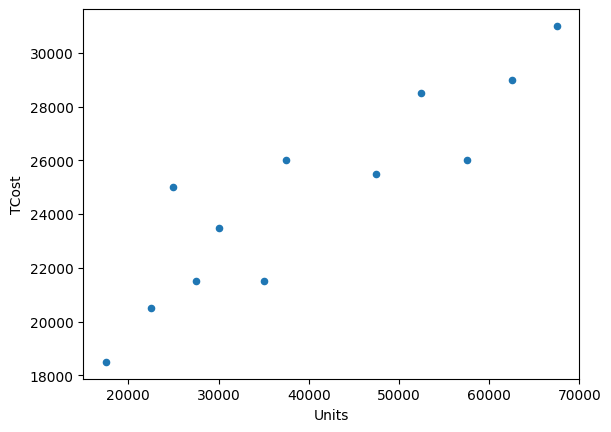

In [8]:
# plot the data

import matplotlib.pyplot as plt
df_costs.plot.scatter(x="Units", y="TCost")
plt.show()

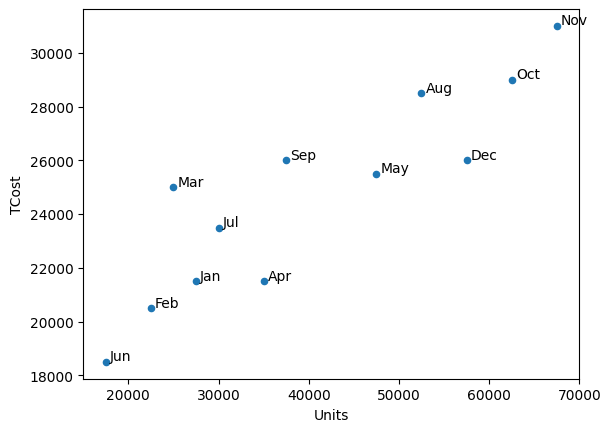

In [14]:
# as before, plot the data but also tag each point with its label

ax = df_costs.plot.scatter(x='Units', y='TCost')

for i, txt in enumerate(df_costs['Month']):
    ax.annotate(
        txt
        , (df_costs['Units'][i], df_costs['TCost'][i])
        , xytext=(3,1)
        , textcoords='offset points'
    )

plt.show()

In [19]:
# Load "statsmodels" which was originally part of pandas, but was separated into its own module

import statsmodels.formula.api as sm

In [20]:
# Run the simple linear regression: OLS = ordinary least squares

slr0 = sm.ols(formula="TCost ~ Units", data=df_costs).fit()

In [23]:
# view a summary of the regression output
slr0.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  TCost   R-squared:                       0.799
Model:                            OLS   Adj. R-squared:                  0.778
Method:                 Least Squares   F-statistic:                     39.65
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           8.95e-05
Time:                        12:09:31   Log-Likelihood:                -105.65
No. Observations:                  12   AIC:                             215.3
Df Residuals:                      10   BIC:                             216.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.669e+04   1371.886     12.164      0.000    1.36e+04    1.97e+04
Units          0.1995      0.032      6.297      0.000       0.129       0.270
==============================================================================
Omnibus:                        0.595   Durbin-Watson:                   2.255
Prob(Omnibus):                  0.743   Jarque-Bera (JB):                0.549
Skew:                           0.410   Prob(JB):                        0.760
Kurtosis:                       2.348   Cond. No.                     1.17e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.17e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [28]:
# access the regression intercept

icept = slr0.params["Intercept"]


In [30]:
# access the regression slope coefficient

slope = slr0.params["Units"]

In [31]:
# create the linear regression object
print(f"Intercept: {icept}, Slope: {slope}")

Intercept: 16688.24417239645, Slope: 0.19946335737045104


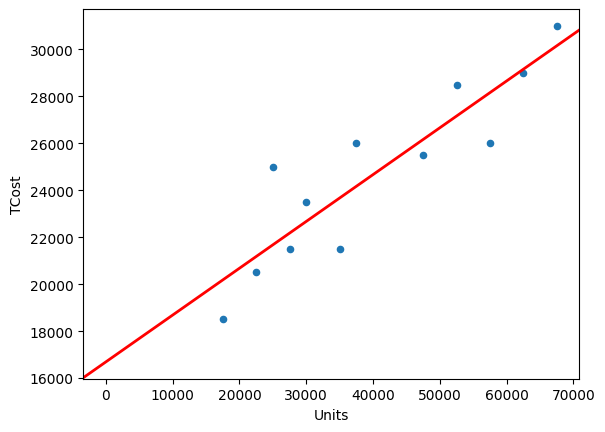

In [34]:
ax2 = df_costs.plot.scatter(x="Units", y="TCost")

ax2.axline((0, icept), slope=slope, color='red', linestyle='-', linewidth=2)

plt.show()